**Проверим данные**

In [8]:
import pandas as pd

df = pd.read_csv('titanic.csv')

print(df.head())
print(df.info())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

Данные в столбцах имеют ожидаемый тип.

**Проанализируем пропуски**

{'PassengerId': 0, 'Survived': 0, 'Pclass': 0, 'Name': 0, 'Sex': 0, 'Age': 177, 'SibSp': 0, 'Parch': 0, 'Ticket': 0, 'Fare': 0, 'Cabin': 687, 'Embarked': 2}


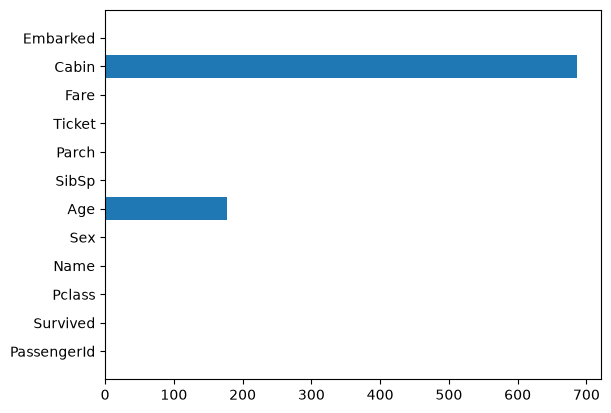

In [14]:
import matplotlib.pyplot as plt

data = df.isna().sum().to_dict()
print(data)

categories = list(data.keys())
values = list(data.values())

plt.barh(categories, values)

plt.show()

Из данных можем заметить, что самое большое количество пропусков находится в столбце "Cabin". Можно предположить, что это произошло потому что каюты фиксировались только за пассажирами выского класса. Пассажиры же низкого класса жили в общих кааютах на несколько человек. Вероятно, не было необходимости их фиксировать.

**Анализируем средний возраст и выживаемость для каждого класса**

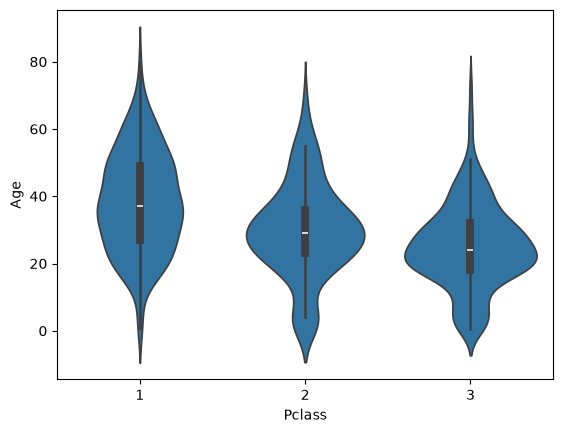

In [32]:
import seaborn as sns

df_without_NaN = df.dropna(subset=['Age'])

sns.violinplot(x='Pclass', y='Age', data=df_without_NaN)

plt.show()


Из данной диаграммы видно, что более высоский уровень класса был у более взрослых людей. То есть богатые пассажиры обычно старше, что вполне ожидаемо.

{1: 0.6296296296296297, 2: 0.47282608695652173, 3: 0.24236252545824846}


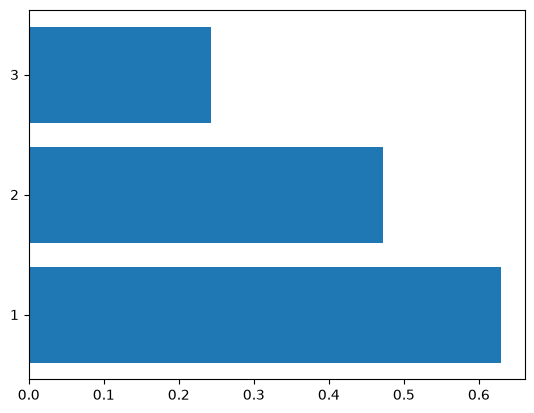

In [25]:
from matplotlib.ticker import MaxNLocator

survival_rate_by_pclass = df.groupby('Pclass')['Survived'].mean().to_dict()

print(survival_rate_by_pclass)

categories_survival = list(survival_rate_by_pclass.keys())
values_survival = list(survival_rate_by_pclass.values())

plt.barh(categories_survival, values_survival)
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

plt.show()

Из данной диаграммы видим, что наибольшая выживаемость была среди людей, имеющих более высокий уровень класса и дорогой билет.

**Рассмотрим данные пассажиров с самыми дорогими билетами**

In [23]:
print(df.sort_values(by='Fare', ascending=False).head(5))

     PassengerId  Survived  Pclass                                Name  \
679          680         1       1  Cardeza, Mr. Thomas Drake Martinez   
258          259         1       1                    Ward, Miss. Anna   
737          738         1       1              Lesurer, Mr. Gustave J   
88            89         1       1          Fortune, Miss. Mabel Helen   
438          439         0       1                   Fortune, Mr. Mark   

        Sex   Age  SibSp  Parch    Ticket      Fare        Cabin Embarked  
679    male  36.0      0      1  PC 17755  512.3292  B51 B53 B55        C  
258  female  35.0      0      0  PC 17755  512.3292          NaN        C  
737    male  35.0      0      0  PC 17755  512.3292         B101        C  
88   female  23.0      3      2     19950  263.0000  C23 C25 C27        S  
438    male  64.0      1      4     19950  263.0000  C23 C25 C27        S  


Видим, что в основом те, у кого более дорогие билеты, старше. Более дорогие билеты также повлияли на выживаемость в основном. По данным, найденным в интернете часть семьи Fortune, Mr. Mark все же смогла спастись. То есть опять же есть влияение стоимости билета на выживаемость. Так же у всех самых дорогих билетов без исключения первый класс, что ожидаемо.